HITO 1

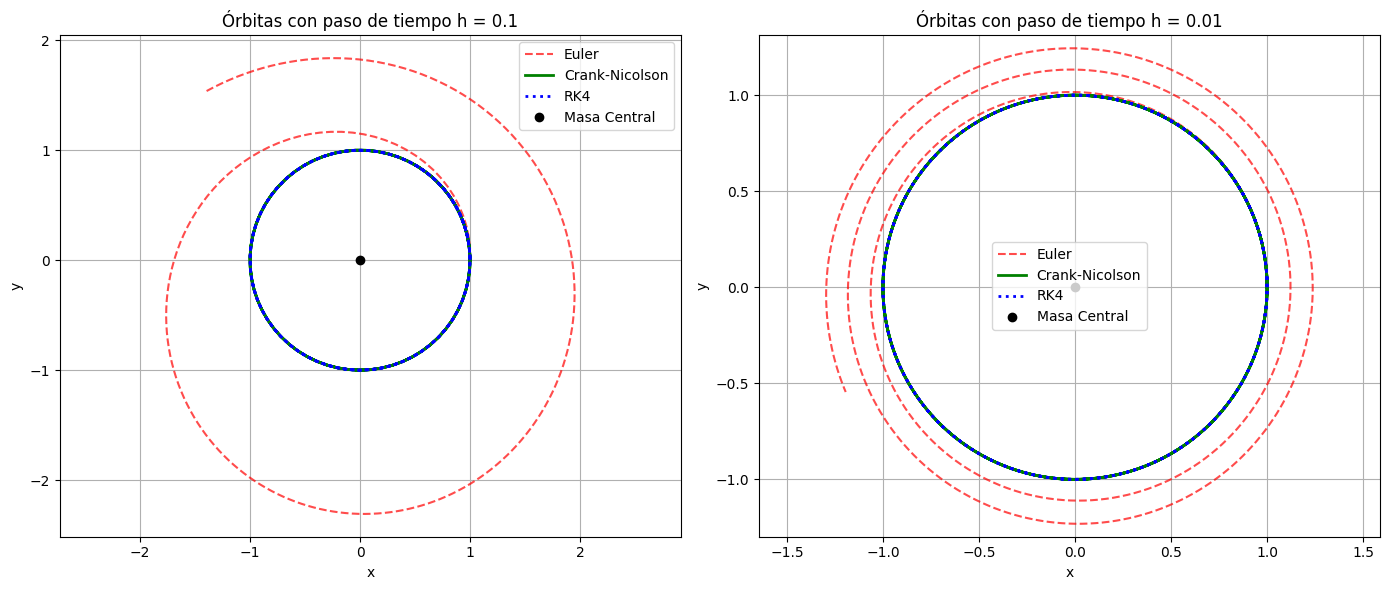

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# 1. Función de derivadas para la dinámica orbital (Problema de 2 cuerpos)
def orbital_dynamics(U):
    """
    Calcula las derivadas [dx/dt, dy/dt, dvx/dt, dvy/dt]
    Vector de estado U = [x, y, vx, vy]
    """
    x, y, vx, vy = U
    r = np.sqrt(x**2 + y**2)
    # Aceleración gravitacional (mu = 1)
    ax = -x / r**3
    ay = -y / r**3
    return np.array([vx, vy, ax, ay])

# 2. Métodos de Integración Independientes
def euler_orbit(U0, t_max, h):
    """Integra la órbita con el método de Euler explícito."""
    times = np.arange(0, t_max, h)
    U = np.zeros((len(times), 4))
    U[0] = U0
    for i in range(len(times) - 1):
        U[i+1] = U[i] + h * orbital_dynamics(U[i])
    return U[:, 0], U[:, 1]

def crank_nicolson_orbit(U0, t_max, h):
    """Integra la órbita con el método de Crank-Nicolson (Implícito)."""
    times = np.arange(0, t_max, h)
    U = np.zeros((len(times), 4))
    U[0] = U0
    
    for i in range(len(times) - 1):
        def residual(U_next):
            return U_next - U[i] - (h / 2.0) * (orbital_dynamics(U[i]) + orbital_dynamics(U_next))
        
        # Predicción inicial con Euler para ayudar a fsolve
        U_guess = U[i] + h * orbital_dynamics(U[i])
        U[i+1] = fsolve(residual, U_guess)
        
    return U[:, 0], U[:, 1]

def rk4_orbit(U0, t_max, h):
    """Integra la órbita con Runge-Kutta de 4to orden."""
    times = np.arange(0, t_max, h)
    U = np.zeros((len(times), 4))
    U[0] = U0
    for i in range(len(times) - 1):
        k1 = orbital_dynamics(U[i])
        k2 = orbital_dynamics(U[i] + 0.5 * h * k1)
        k3 = orbital_dynamics(U[i] + 0.5 * h * k2)
        k4 = orbital_dynamics(U[i] + h * k3)
        U[i+1] = U[i] + (h / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    return U[:, 0], U[:, 1]

# 3. Configuración y ejecución de la simulación
# Condición inicial para órbita circular de radio 1
U0_circular = np.array([1.0, 0.0, 0.0, 1.0])
t_simulacion = 20.0  # Tiempo suficiente para varias revoluciones
pasos_de_tiempo = [0.1, 0.01]  # Variación del paso de tiempo (h)

# 4. Graficación
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

for idx, h in enumerate(pasos_de_tiempo):
    # Ejecutar los tres métodos
    x_e, y_e = euler_orbit(U0_circular, t_simulacion, h)
    x_cn, y_cn = crank_nicolson_orbit(U0_circular, t_simulacion, h)
    x_rk, y_rk = rk4_orbit(U0_circular, t_simulacion, h)
    
    # Dibujar resultados
    axs[idx].plot(x_e, y_e, 'r--', label='Euler', alpha=0.7)
    axs[idx].plot(x_cn, y_cn, 'g-', label='Crank-Nicolson', linewidth=2)
    axs[idx].plot(x_rk, y_rk, 'b:', label='RK4', linewidth=2)
    axs[idx].plot(0, 0, 'ko', label='Masa Central')
    
    axs[idx].set_title(f'Órbitas con paso de tiempo h = {h}')
    axs[idx].set_xlabel('x')
    axs[idx].set_ylabel('y')
    axs[idx].axis('equal')
    axs[idx].grid(True)
    axs[idx].legend()

plt.tight_layout()
plt.show()

HITO 2

(1. 2. 3. 4.) TODAS LAS FUNCIONES

In [10]:
def Euler(F, U, t, h):
    """
    Integra un paso usando el método de Euler explícito.
    """
    return U + h * F(U, t)

def Crank_Nicolson(F, U, t, h):
    """
    Integra un paso usando el método implícito de Crank-Nicolson.
    """
    def residual(U_next):
        # La ecuación residual que fsolve intentará igualar a cero
        return U_next - U - (h / 2.0) * (F(U, t) + F(U_next, t + h))
    
    # Se utiliza el paso de Euler explícito como estimación inicial
    U_guess = Euler(F, U, t, h)
    
    # fsolve devuelve un array; si U es escalar, extraemos el valor
    U_next = fsolve(residual, U_guess)
    return U_next if U_next.size > 1 else U_next[0]

def RK4(F, U, t, h):
    """
    Integra un paso usando el método de Runge-Kutta de 4to orden.
    """
    k1 = F(U, t)
    k2 = F(U + 0.5 * h * k1, t + 0.5 * h)
    k3 = F(U + 0.5 * h * k2, t + 0.5 * h)
    k4 = F(U + h * k3, t + h)
    
    return U + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

def Inverse_Euler(F, U, t, h):
    """
    Integra un paso usando el método de Euler Inverso (Implícito).
    """
    def residual(U_next):
        # La ecuación residual para Euler Implícito
        return U_next - U - h * F(U_next, t + h)
    
    # Estimación inicial
    U_guess = Euler(F, U, t, h)
    U_next = fsolve(residual, U_guess)
    return U_next if U_next.size > 1 else U_next[0]

5. INTEGRACIÓN DEL PROBLEMA DE CAUCHY

In [11]:
def integrate_cauchy(scheme, F, U0, t_array):
    """
    Integra un problema de Cauchy.
    
    Parámetros:
    - scheme: Función del esquema temporal a usar (ej. Euler, RK4).
    - F: Función F(U, t) del problema de Cauchy.
    - U0: Condición inicial (puede ser escalar o un array de NumPy).
    - t_array: Array de NumPy con los instantes de tiempo donde se evaluará.
    
    Retorna:
    - U: Array con la solución en cada instante de tiempo.
    """
    # Determinamos el número de pasos de tiempo
    num_steps = len(t_array)
    
    # Preparamos el array para almacenar la solución
    # Verifica si U0 es un escalar o un vector (para sistemas de ecuaciones)
    if isinstance(U0, (int, float)):
        U = np.zeros(num_steps)
    else:
        U = np.zeros((num_steps, len(U0)))
        
    # Aplicamos la condición inicial
    U[0] = U0
    
    # Bucle de integración temporal
    for i in range(num_steps - 1):
        t = t_array[i]
        # Calculamos el tamaño del paso de tiempo actual (h)
        h = t_array[i+1] - t_array[i]
        
        # Invocamos el esquema temporal pasado como argumento
        U[i+1] = scheme(F, U[i], t, h)
        
    return U

6. FUERZA KEPLER, EJEMPLO DE F

In [12]:
def kepler_F(U, t=0):
    """
    Expresa la fuerza del movimiento de Kepler para el problema de Cauchy.
    U es el vector de estado de 4 dimensiones [x, y, vx, vy].
    """
    # Extraemos los sub-vectores de R^2 usando slicing
    r = U[0:2]       # Vector de posición [x, y]
    r_dot = U[2:4]   # Vector de velocidad (derivada de r) [vx, vy]
    
    # Calculamos la norma (magnitud) del vector r: |r|
    r_norm = np.linalg.norm(r)
    
    # Calculamos la segunda derivada (aceleración): -r / |r|^3
    r_ddot = -r / (r_norm**3)
    
    # Ensamblamos el vector de salida F = [r_dot, r_ddot]
    return np.concatenate((r_dot, r_ddot))

(7. 8.) INTEGRAIÓN DE UNA ÓRBITA

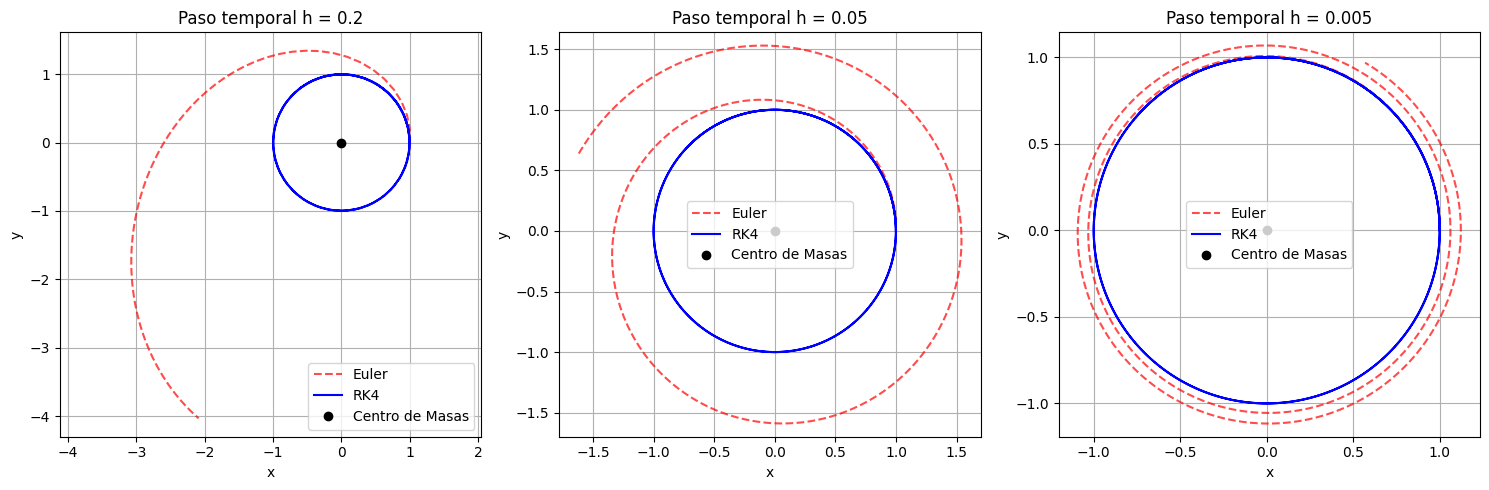

In [13]:
# 1. Condición inicial (órbita circular: x=1, y=0, vx=0, vy=1)
U0 = np.array([1.0, 0.0, 0.0, 1.0])  
t_simulacion = 15.0                  

# 2. Pasos de tiempo a evaluar (de mayor a menor)
pasos_tiempo = [0.2, 0.05, 0.005]    

# 3. Configuración del lienzo
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for i, h in enumerate(pasos_tiempo):
    # Creamos el vector de tiempo específico para este h
    t_array = np.arange(0, t_simulacion, h)
    
    # Invocamos la función envoltorio 'integrate_cauchy' pasándole los esquemas temporales
    solucion_euler = integrate_cauchy(Euler, kepler_F, U0, t_array)
    solucion_rk4 = integrate_cauchy(RK4, kepler_F, U0, t_array)
    
    # Extraemos las coordenadas espaciales (columnas 0 y 1)
    x_euler, y_euler = solucion_euler[:, 0], solucion_euler[:, 1]
    x_rk4, y_rk4 = solucion_rk4[:, 0], solucion_rk4[:, 1]
    
    # Dibujamos las trayectorias
    axs[i].plot(x_euler, y_euler, 'r--', label='Euler', alpha=0.7)
    axs[i].plot(x_rk4, y_rk4, 'b-', label='RK4', linewidth=1.5)
    axs[i].plot(0, 0, 'ko', label='Centro de Masas')
    
    axs[i].set_title(f'Paso temporal h = {h}')
    axs[i].set_xlabel('x')
    axs[i].set_ylabel('y')
    axs[i].axis('equal')
    axs[i].grid(True)
    axs[i].legend()

plt.tight_layout()
plt.show()

HITO 3

1. ERROR RICHARDSON


In [14]:
def richardson_error(scheme, F, U0, t_array, q=None):
    """
    Evalúa el error numérico de integración mediante extrapolación de Richardson,
    basándose en la solución del problema de Cauchy del Hito 2.
    
    Parámetros:
    - scheme: Esquema temporal (Euler, Inverse_Euler, Crank_Nicolson, RK4).
    - F: Función F(U, t) del sistema.
    - U0: Condición inicial.
    - t_array: Partición temporal gruesa de paso h (N+1 nodos: de 0 a N).
    - q: Orden teórico del esquema temporal (opcional).
    
    Retorna:
    - error: Array con el vector de error estimado en cada instante de t_array.
    """
    N = len(t_array) - 1
    # Creamos la malla fina t2 con el doble de pasos (paso h/2) -> 2*N + 1 nodos
    t_fine = np.linspace(t_array[0], t_array[-1], 2 * N + 1)
    
    # Integramos el problema de Cauchy en ambas mallas
    U_coarse = integrate_cauchy(scheme, F, U0, t_array)
    U_fine = integrate_cauchy(scheme, F, U0, t_fine)
    
    # Los instantes de t_array coinciden exactamente con los índices pares de t_fine (0, 2, 4...)
    diff = U_fine[0::2] - U_coarse
    
    # Aplicamos el factor de corrección de Richardson si se especifica el orden q
    if q is not None:
        error = diff / (1.0 - (0.5)**q)
    else:
        error = diff
        
    return error

2. APLICANDO LOS ESQUEMAS

C:\Users\Dani\AppData\Local\Temp\ipykernel_992\2624103029.py:43: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  U_next = fsolve(residual, U_guess)
C:\Users\Dani\AppData\Local\Temp\ipykernel_992\2624103029.py:43: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last five Jacobian evaluations.
  U_next = fsolve(residual, U_guess)


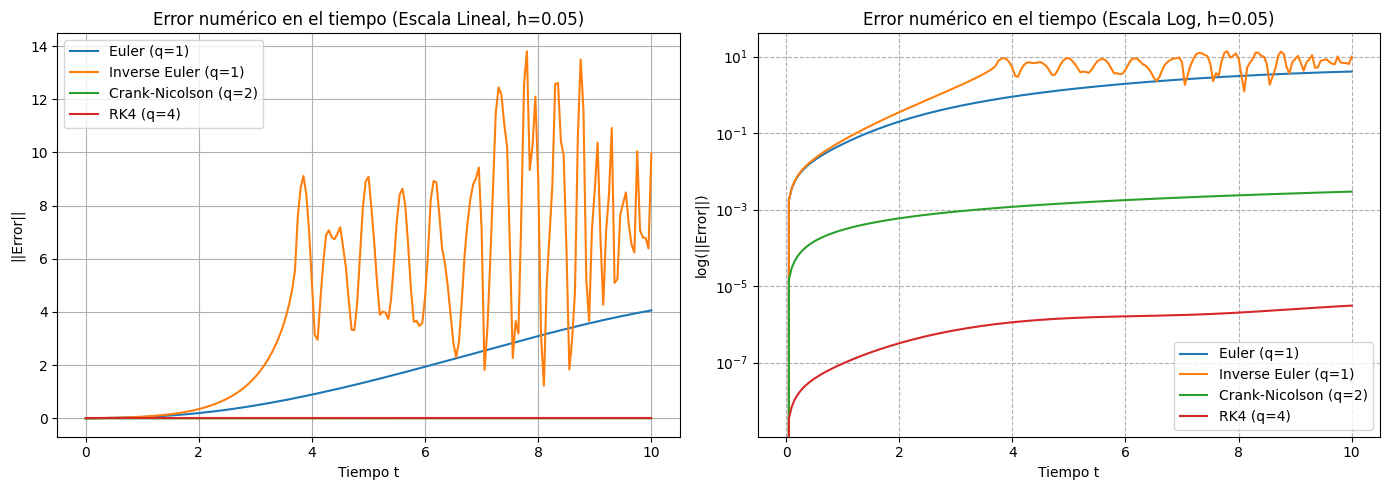

In [15]:
# Condiciones iniciales y malla temporal base
U0 = np.array([1.0, 0.0, 0.0, 1.0])
t_final = 10.0
h = 0.05
t_array = np.arange(0, t_final + h, h)

# Diccionario con los esquemas y sus órdenes teóricos (q)
esquemas = [
    ("Euler", Euler, 1),
    ("Inverse Euler", Inverse_Euler, 1),
    ("Crank-Nicolson", Crank_Nicolson, 2),
    ("RK4", RK4, 4)
]

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for nombre, func_esquema, orden_q in esquemas:
    # Calculamos el vector de error en cada instante (dimensión: num_steps x 4)
    err_vec = richardson_error(func_esquema, kepler_F, U0, t_array, q=orden_q)
    
    # Calculamos la norma euclídea del error en cada instante de tiempo
    err_norm = np.linalg.norm(err_vec, axis=1)
    
    # Gráfica en escala lineal
    axs[0].plot(t_array, err_norm, label=f"{nombre} (q={orden_q})")
    # Gráfica en escala logarítmica (ideal para apreciar RK4 junto a Euler)
    axs[1].semilogy(t_array, err_norm, label=f"{nombre} (q={orden_q})")

axs[0].set_title(f"Error numérico en el tiempo (Escala Lineal, h={h})")
axs[0].set_xlabel("Tiempo t")
axs[0].set_ylabel("||Error||")
axs[0].grid(True)
axs[0].legend()

axs[1].set_title(f"Error numérico en el tiempo (Escala Log, h={h})")
axs[1].set_xlabel("Tiempo t")
axs[1].set_ylabel("log(||Error||)")
axs[1].grid(True, which="both", ls="--")
axs[1].legend()

plt.tight_layout()
plt.show()

3. RATIO DE CONVERGENCIA

In [16]:
def evaluate_convergence_rate(scheme, F, U0, t_final, N_inicial, num_refinamientos):
    """
    Evalúa el error final y la tasa de convergencia de un esquema temporal 
    variando el tamaño del paso de tiempo (h).
    
    Parámetros:
    - scheme: Esquema temporal a evaluar.
    - F: Función del sistema F(U, t).
    - U0: Condición inicial.
    - t_final: Tiempo final de integración.
    - N_inicial: Número de pasos de la malla más gruesa.
    - num_refinamientos: Número de veces que se duplicará el número de pasos N.
    
    Retorna:
    - log_N: Array con log10(N) (o se puede usar log10(h)).
    - log_E: Array con log10(||Error(t_final)||).
    - orden_q: Pendiente de la regresión lineal (tasa de convergencia estimada).
    """
    log_N = np.zeros(num_refinamientos)
    log_E = np.zeros(num_refinamientos)
    
    N = N_inicial
    for i in range(num_refinamientos):
        t_array = np.linspace(0, t_final, N + 1)
        
        # Calculamos el error mediante Richardson (sin asumir q a priori)
        err_vec = richardson_error(scheme, F, U0, t_array, q=None)
        
        # Tomamos la norma del error en el instante final t_final
        err_final = np.linalg.norm(err_vec[-1])
        
        log_N[i] = np.log10(N)
        log_E[i] = np.log10(err_final)
        
        # Duplicamos el número de pasos (h se divide por 2) para el siguiente punto
        N = 2 * N
        
    # Ajuste lineal: log10(E) = -q * log10(N) + cte
    pendiente, _ = np.polyfit(log_N, log_E, 1)
    orden_q = -pendiente
    
    return log_N, log_E, orden_q

4. APLICANDO LOS ESQUEMAS

--- TASAS DE CONVERGENCIA ESTIMADAS (Orden q) ---
Euler           -> Orden estimado q = 0.88 (Teórico: 1)
Inverse Euler   -> Orden estimado q = 1.21 (Teórico: 1)
Crank-Nicolson  -> Orden estimado q = 2.00 (Teórico: 2)
RK4             -> Orden estimado q = 4.01 (Teórico: 4)


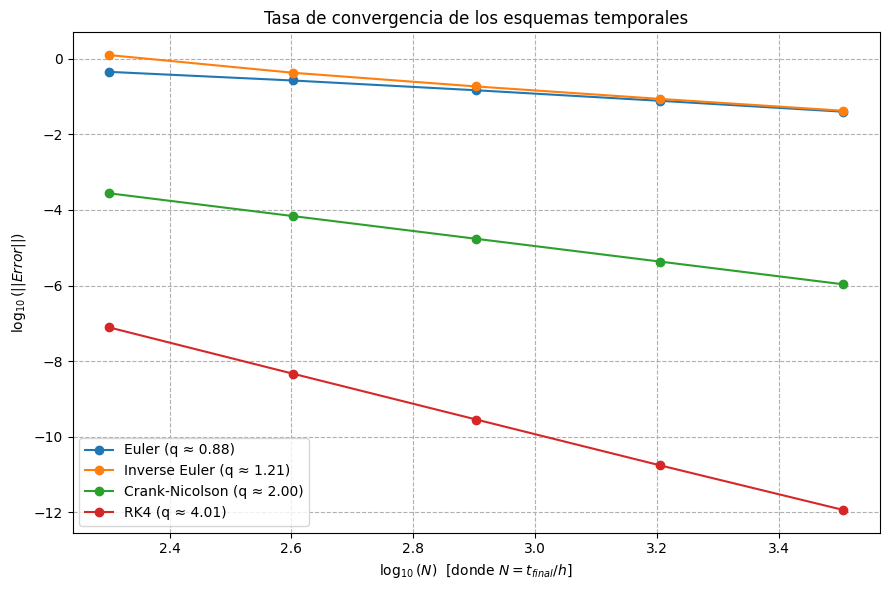

In [17]:
# Parámetros para el estudio de convergencia
U0 = np.array([1.0, 0.0, 0.0, 1.0])
t_final = 5.0          # Tiempo final de integración
N_inicial = 200        # Empezamos con N=500 pasos (h = 0.01)
num_refinamientos = 5  # Evaluará N = 500, 1000, 2000, 4000, 8000

plt.figure(figsize=(9, 6))

print("--- TASAS DE CONVERGENCIA ESTIMADAS (Orden q) ---")
for nombre, func_esquema, q_teorico in esquemas:
    log_N, log_E, q_estimado = evaluate_convergence_rate(
        func_esquema, kepler_F, U0, t_final, N_inicial, num_refinamientos
    )
    
    print(f"{nombre:15s} -> Orden estimado q = {q_estimado:.2f} (Teórico: {q_teorico})")
    
    # Graficamos los puntos obtenidos y la línea de tendencia
    plt.plot(log_N, log_E, 'o-', linewidth=1.5, 
             label=f"{nombre} (q ≈ {q_estimado:.2f})")

plt.title("Tasa de convergencia de los esquemas temporales")
plt.xlabel(r"$\log_{10}(N)$  [donde $N = t_{final} / h$]")
plt.ylabel(r"$\log_{10}(||Error||)$")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()